#최종결과

## 수면-각성 탐지 모델 개발 최종 보고서

## 프로젝트 개요
본 프로젝트는 `sleep-edf-database-expanded-1.0.0`에서 제공하는 EDF 형식의 수면다원검사(PSG) 데이터와 Muse 뇌파(EEG) 데이터를 활용하여 수면-각성 상태를 자동으로 탐지하는 딥러닝 모델을 개발하는 것을 목표로 합니다. 데이터 전처리, 딥러닝 모델 구축 및 학습, 활동성 기반 미세 조정, 그리고 최종 성능 평가에 이르는 전 과정을 다룹니다.

## 1. 수면 원격 측정 데이터 전처리 및 `.fif`, `.npy` 변환

### 3.1 EDF 데이터 로딩 및 정보 확인
- **데이터 경로 정의**: `base_dir`을 `/content/drive/MyDrive/sleep-telemetry/sleep-edf-database-expanded-1.0.0/sleep-telemetry`로 설정하고, `first_path_list`와 `second_path_list`에 정의된 고유 식별자를 사용하여 PSG(`-PSG.edf`) 파일과 Hypnogram(`-Hypnogram.edf`) 파일의 전체 경로를 생성했습니다. `paired_paths`를 통해 각 환자별 PSG와 Hypnogram 파일이 올바르게 매칭되었음을 확인했습니다.
- **EDF 파일 정보 확인**: `pyedflib.EdfReader`를 사용하여 각 PSG 파일의 헤더 정보와 채널별 상세 정보(채널명, 샘플 수, 단위)를 출력하여 데이터 구조를 파악했습니다. `EEG Fpz-Cz`, `EEG Pz-Oz`, `EOG horizontal`, `EMG submental`, `Marker` 등의 채널이 포함되어 있으며, 뇌파 분석의 핵심 채널인 `EEG Fpz-Cz`와 `EEG Pz-Oz`에 집중했습니다.

### 3.2 뇌파 채널 선택 및 `.fif` 변환
- `mne` 라이브러리를 사용하여 EDF 파일을 읽고, `EEG Fpz-Cz`와 `EEG Pz-Oz` 두 채널만 선택한 후 MNE의 자체 이진 형식인 `.fif` 파일로 `/content/drive/MyDrive/sleep-telemetry/sleep_fif` 경로에 저장했습니다.
- **근거**: `.fif` 형식은 MNE에 최적화된 파일 형식으로, 빠른 데이터 로딩과 효율적인 저장을 가능하게 합니다. 불필요한 채널을 미리 제거하여 후속 처리 단계를 단순화하고 계산 효율성을 높였습니다.

### 3.3 데이터 병합 및 `.npy` 변환 (수면 단계 분류를 위한 에포크 생성)
- `stage_map`을 정의하여 EDF Hypnogram 파일의 텍스트 기반 수면 단계 주석을 수치형 레이블(0, 1, 2, 3, 4, 5)로 매핑했습니다.
- `time_step_sec = 30`으로 30초를 하나의 수면 에포크(epoch) 단위로 설정했습니다. 이는 수면 단계 분류의 표준 관행입니다.
- 각 `.fif` 파일에서 원시 데이터를 로드하고, Hypnogram 파일에서 읽은 주석을 `sfreq` (샘플링 주파수)를 사용하여 각 샘플에 해당하는 수면 단계 레이블 배열로 변환했습니다.
- 전체 데이터를 30초 간격으로 슬라이딩하여 `X` (데이터 윈도우)와 `Y` (해당 윈도우의 가장 빈번한 수면 단계 레이블)를 생성했습니다. `np.bincount(labels[i:i+time_step]).argmax()`를 사용하여 30초 내에서 가장 많이 나타나는 수면 단계를 해당 에포크의 대표 레이블로 지정했습니다.
- 생성된 `X`와 `Y` 데이터를 `/content/drive/MyDrive/sleep-telemetry/merge_dataset_tel` 경로에 NumPy의 바이너리 형식인 `.npy` 파일로 저장했습니다.
- **근거**: `.npy` 형식은 데이터 누수 방지 및 효율적인 I/O를 제공하여 대용량 시계열 데이터 처리 및 기계 학습 모델 입력에 매우 적합합니다.

## 2. 초기 딥러닝 모델 개발 및 학습

### 2.1 데이터 로딩 및 준비
- Google Drive에서 `/content/drive/MyDrive/sleep-telemetry/muse_merge_dataset_tel` 경로의 `.npy` 파일을 `/content/dataset` 로컬 디렉토리로 복사하여 학습 효율성을 높였습니다. 16명의 피험자 중 11명은 학습, 3명은 검증, 2명은 테스트 데이터로 분할했습니다.
- **하이퍼파라미터**: `BATCH_SIZE = 32`, `SAMPLING_RATE = 256`, `SEQ_SEC = 5`, `STRIDE_SEC = 5`, `SEQ_LEN = 1280`으로 설정되었습니다.

### 2.2 전처리 및 데이터 증강
- **전처리 함수**: `bandpass_filter` (0.5-40Hz 대역 통과 필터) 및 `is_noisy` (노이즈 샘플 제거) 함수가 정의되었습니다. 각 샘플은 표준화(`Z-score normalization`) 과정을 거쳤습니다.
- **데이터 제너레이터 (`data_generator`)**: 데이터 불균형 해소를 위해 Wake(0)과 Sleep(1) 샘플의 비율을 조절하고, 학습 데이터에 대해 임의 노이즈 추가 및 스케일링을 통한 데이터 증강을 적용했습니다.

### 2.3 모델 아키텍처 및 학습
- **모델 아키텍처 (`build_model`)**:
    - 입력 레이어 `(SEQ_LEN, 2)`.
    - `Conv1D` (32, 7), `BatchNormalization`, `MaxPooling1D` (4).
    - `Conv1D` (64, 5), `BatchNormalization`, `MaxPooling1D` (4).
    - `Bidirectional GRU` (32)를 통한 시퀀스 학습.
    - **어텐션 메커니즘**: `Dense(1, activation='tanh')`와 `Softmax`를 활용하여 시퀀스 내 중요한 특징에 가중치를 부여했습니다.
    - `GlobalAveragePooling1D`를 사용하여 `Lambda` 레이어 사용 시 발생할 수 있는 모델 저장/로드 에러를 방지했습니다.
    - `Dropout` (0.4), `Dense` (16, relu), `Dense` (1, sigmoid)를 통한 최종 분류.
- **컴파일**: `Adam` (1e-4), `binary_crossentropy`, `accuracy`.
- **학습 진행**: `train_ds`와 `val_ds`는 `tf.data.Dataset.from_generator`를 통해 생성되었으며, `EarlyStopping` (patience=7) 콜백을 사용하여 과적합을 방지했습니다.

### 2.4 초기 학습 결과 및 모델 저장
- **평가**: `find_best_threshold` 함수를 통해 최적의 분류 임계값(F1-score 기반)을 탐색하고, `evaluate` 함수로 최종 성능(precision, recall, f1-score)을 평가했습니다.
- **초기 학습 결과**: 15 epoch까지 학습을 진행한 결과, 검증 세트에서 안정적인 성능을 보였습니다. 최종적으로 테스트 세트에서 최적 임계값 0.779를 사용했을 때, 전체 정확도 95%의 결과를 얻었습니다. Wake 클래스(0)에 대한 Precision 0.98, Recall 0.95, Sleep 클래스(1)에 대한 Precision 0.85, Recall 0.94를 기록하여 높은 분류 성능을 확인했습니다.
- **모델 저장**: 학습된 모델 (`MUSE2_Attention_Final.keras`)과 가중치 (`MUSE2_Attention_Weights.weights.h5`)는 `/content/drive/MyDrive/sleep-telemetry/` 경로에 저장되었습니다.

## 3. 데이터 분포 분석

모델 학습에 앞서, 데이터셋의 클래스 불균형 문제를 확인하기 위해 `analyze_dataset_distribution` 함수를 통해 전체 피험자별 Wake/Sleep 비율을 분석했습니다.
- **분석 대상**: `/content/dataset` 경로에 복사된 `Y_ST7{fid}-PSG.npy` 파일들을 분석했습니다.
- **Wake/Sleep 정의**: Sleep-EDF 원본 기준 0을 Wake로, 그 외 모든 수면 단계(1, 2, 3, 4, R)를 Sleep으로 간주했습니다.
- **결과**: 피험자별로 Sleep 비율이 53.40%에서 92.90%까지 다양하게 나타났으며, 전체 데이터 평균 졸음 비율은 81.86%로 Sleep 클래스가 압도적으로 많아 데이터 불균형이 존재함을 확인했습니다. 이는 모델 학습 시 Wake 클래스에 대한 학습 부족을 야기할 수 있음을 시사했습니다.

## 4. 활동성 기반 미세 조정 (Finetuning) 모델 개발

초기 모델의 전이 학습을 활용하여 활동성(Activity) 기반으로 수면-각성 분류를 보다 정교하게 수행하는 파인튜닝 모델을 개발했습니다.

### 4.1 새로운 데이터셋 및 활동성 기반 라벨링
- **새로운 데이터셋**: `/content/awake_study.csv`, `/content/awake_study2.csv`, `/content/awake_study3.csv`, `/content/bedtime.csv`, `/content/bedtime2.csv`와 같은 CSV 형식의 Muse 데이터를 활용했습니다. 이 데이터는 실제 사용 환경에 가까운 데이터를 모의하기 위해 사용되었습니다.
- **활동성(Activity) 기반 라벨링**: EEG 신호의 활동성을 측정하는 `get_activity` (절대값 미분 평균)와 `get_spike_ratio` (스파이크 비율) 함수를 정의했습니다. `get_activity`를 통해 전체 데이터의 활동성 분포를 파악하고, `low_thr` (30th percentile)과 `high_thr` (70th percentile)을 설정하여 **Sleep-like (0.0)** 및 **Awake-like (1.0)** 라벨을 자동으로 생성했습니다. 이는 EEG 신호 자체의 특성을 활용하여 수면-각성 구간을 구분하는 새로운 접근법입니다.
    - `GLOBAL ACTIVITY THRESHOLD` 결과: LOW: 0.505, HIGH: 0.869로 설정되었습니다.

### 4.2 데이터 증강 및 미세 조정 학습
- **데이터 증강**: `augment` 함수를 통해 학습 데이터에 노이즈와 스케일링을 적용하여 모델의 강건함을 높였습니다.
- **미세 조정 모델 구조**: 이전에 학습된 모델 (`MUSE_pretrained_2.keras`)을 불러와 모든 레이어를 `trainable=True`로 설정하고 미세 조정했습니다. 옵티마이저, 손실 함수, 지표는 초기 모델과 동일하게 사용했습니다.
- **미세 조정 학습**: `train_ds`와 `val_ds`는 `muse_generator`를 통해 활동성 기반으로 라벨링된 데이터를 사용하여 생성되었습니다. `steps_per_epoch=25`, `validation_steps=10`, `epochs=20`으로 설정되었으며, `EarlyStopping` (patience=3) 콜백을 적용했습니다.

### 4.3 미세 조정 학습 결과 및 모델 저장
- **학습 결과**: 미세 조정 학습 과정에서 Loss가 점진적으로 감소하고 Accuracy가 향상되는 것을 확인했습니다. 최종적으로 Epoch 20에서 가장 좋은 성능을 달성하여 가중치가 복원되었습니다.
- **모델 저장**: 미세 조정된 모델 (`MUSE_activity_model.keras`)과 가중치 (`MUSE_activity_weights.weights.h5`)는 `/content/drive/MyDrive/sleep-telemetry` 경로에 저장되었습니다.

## 5. 추론 및 시각화

미세 조정된 모델을 사용하여 새로운 데이터에 대한 수면-각성 추론을 수행하고, 결과를 시각화하여 모델의 작동 방식을 직관적으로 이해했습니다.
- **모델 로드**: `/content/drive/MyDrive/sleep-telemetry/MUSE_activity_model.keras`에 저장된 미세 조정 모델을 로드했습니다. Keras의 `safe_mode=False` 옵션을 사용하여 모든 커스텀 레이어(특히 `Lambda` 레이어 대체 전)가 올바르게 로드되도록 했습니다.
- **전처리**: `bandpass` 필터링, 중앙값 제거, 클리핑, Z-score 정규화 등의 과정을 거쳤습니다.
- **이력 현상(Hysteresis) 적용**: `hysteresis` 함수를 사용하여 모델의 확률 예측값에 기반하여 최종 수면-각성 상태(0: Sleep, 1: Awake)를 결정했습니다. `high=0.55`, `low=0.45` 임계값을 적용하여 전환 구간에서의 불안정성을 줄였습니다.
- **추론 및 시각화 (`run_inference`)**: `awake_study.csv`와 `bedtime.csv` 파일을 대상으로 추론을 실행하고, 시간에 따른 Awake 확률과 이력 현상이 적용된 예측 상태를 그래프로 시각화했습니다. 이를 통해 모델이 실제 EEG 신호 변화에 어떻게 반응하여 수면-각성 상태를 추정하는지 확인했습니다.

## 6. 개선된 추론 및 최종 평가

모델의 예측 결과가 특정 구간에 집중되는 경향을 개선하고, 보다 명확한 수면-각성 분류를 위해 확률값 스케일링을 추가한 추론 프로세스를 도입했습니다.

- **추론 개선 (`run_all_inference_v2`)**: 기존 추론 방식에서 모델 예측 확률이 0.5 근처에 밀집되는 문제를 해결하기 위해, 각 파일별 예측 확률 (`preds`)에 대해 **Min-Max Scaling**을 적용하여 0과 1 사이로 강제로 분포를 확장했습니다. (`preds_scaled = (preds - np.min(preds)) / (np.max(preds) - np.min(preds) + 1e-6)`).
- **확실한 분류**: 스케일링된 `preds_scaled`에 `hysteresis` 함수를 다시 적용하여 0.5를 기준으로 보다 명확하게 수면-각성 상태를 분류했습니다.
- **시각화**: 개선된 추론 결과를 `awake_study.csv`, `awake_study2.csv`, `awake_study3.csv`, `bedtime.csv`, `bedtime2.csv` 파일에 대해 시각화하여, 스케일링을 통해 예측 확률 분포가 0~1 전체 범위로 확대되고 수면-각성 전환이 더욱 뚜렷하게 나타나는 것을 확인했습니다.
- **통합 혼동 행렬 (`plot_integrated_confusion_matrix`)**: `awake_study.csv`와 `bedtime.csv` 두 파일을 대상으로 통합 혼동 행렬 및 분류 보고서를 생성하여 최종 모델의 성능을 정량적으로 평가했습니다.
    - **결과**: Sleep 클래스에 대한 Precision 0.52, Recall 0.79, F1-score 0.63을, Awake 클래스에 대한 Precision 0.56, Recall 0.27, F1-score 0.37을 기록했습니다. 전체 정확도는 0.53으로 나타났습니다. Awake 클래스에 대한 Recall이 상대적으로 낮은 것은 활동성이 낮은 Awake 구간을 Sleep으로 오분류하는 경향이 있음을 시사합니다. 이는 활동성 기반 라벨링의 한계일 수 있으며, 실제 PSG 데이터를 통한 라벨링과의 차이에서 기인할 수 있습니다.
- **성과**: Min-Max Scaling을 통해 모델의 예측 분포를 효과적으로 확장하여 시각적으로 더 명확한 분류 결과를 얻었습니다. 하지만, 활동성 기반의 단순한 0/1 라벨링은 실제 수면 단계의 복잡성을 완전히 반영하지 못하여, 특히 Awake 클래스에서 Recall 값이 낮은 한계점을 보였습니다.

## 7. 결론 및 향후 계획

본 프로젝트를 통해 Muse 뇌파 데이터를 활용한 수면-각성 탐지 모델을 성공적으로 개발하고, 여러 단계의 전처리, 모델 구축, 학습 및 미세 조정을 거쳤습니다. 특히 EDF 데이터를 `.fif`와 `.npy`로 변환하는 과정에서 데이터 처리의 효율성을 크게 높였으며, 어텐션 메커니즘을 포함한 딥러닝 모델을 통해 시계열 뇌파 데이터의 특징을 효과적으로 학습했습니다.

활동성 기반의 라벨링을 통해 실제 환경과 유사한 데이터를 활용한 미세 조정을 시도했으나, 이 라벨링 방식이 실제 수면 단계와 완벽하게 일치하지 않아 Awake 클래스에서 Recall 성능에 한계가 있음을 확인했습니다. 이는 활동성이 낮은 각성 상태(조용한 각성)를 수면으로 오분류할 가능성을 내포합니다.

**향후 계획**:
1.  **다중 수면 단계 분류 확장**: 현재 이진 분류(수면/각성) 모델을 N1, N2, N3, REM 등 더 세분화된 수면 단계 분류 모델로 확장하는 것을 고려할 수 있습니다. 이를 위해서는 보다 정교한 수면 단계 라벨링 데이터셋과 다중 클래스 분류에 적합한 모델 구조 및 손실 함수가 필요합니다.
2.  **전처리 개선**: EEG 신호 외에 EOG(안구 운동) 및 EMG(근전도) 신호를 추가적으로 활용하여 모델의 분류 정확도를 높일 수 있습니다. 또한, 주파수 도메인 특징(예: FFT, 웨이블릿 변환)을 추출하여 모델 입력으로 사용하는 방안도 탐색할 수 있습니다.
3.  **데이터셋 확장 및 균형**: 더 많은 피험자 데이터와 다양한 수면 패턴을 포함하는 데이터셋을 확보하고, 각 수면 단계의 샘플 수를 균형 있게 조절하여 모델의 일반화 성능을 향상시킬 수 있습니다.
4.  **모델 최적화**: 경량화된 모델 아키텍처 (예: MobileNet 계열, EfficientNet)를 적용하여 임베디드 장치나 모바일 환경에서도 효율적으로 동작하는 모델을 개발할 수 있습니다.
5.  **실시간 추론 고려**: 모델의 추론 속도를 최적화하여 실시간 또는 준실시간 수면-각성 모니터링 시스템에 적용 가능성을 탐색할 수 있습니다.

#edf기반 기초 model

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 128s 398ms/step - accuracy: 0.8493 - loss: 0.3639 - val_accuracy: 0.9595 - val_loss: 0.1278
Epoch 2/50
  1/300 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9062 - loss: 0.3025

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


300/300 ━━━━━━━━━━━━━━━━━━━━ 94s 313ms/step - accuracy: 0.9364 - loss: 0.1846 - val_accuracy: 0.9480 - val_loss: 0.1253
Epoch 3/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 99s 333ms/step - accuracy: 0.9235 - loss: 0.2137 - val_accuracy: 0.9146 - val_loss: 0.2267
Epoch 4/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 140s 467ms/step - accuracy: 0.9249 - loss: 0.2120 - val_accuracy: 0.9097 - val_loss: 0.2002
Epoch 5/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 77s 257ms/step - accuracy: 0.9435 - loss: 0.1719 - val_accuracy: 0.9165 - val_loss: 0.2110
Epoch 6/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 84s 279ms/step - accuracy: 0.9566 - loss: 0.1508 - val_accuracy: 0.9471 - val_loss: 0.1705
Epoch 7/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 55s 184ms/step - accuracy: 0.9745 - loss: 0.0915 - val_accuracy: 0.9425 - val_loss: 0.1362
Epoch 8/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 70s 233ms/step - accuracy: 0.9747 - loss: 0.0863 - val_accuracy: 0.9582 - val_loss: 0.0972
Epoch 9/50
300/300 ━━━━━━━━━━━━━━━━━━━━ 61s 204ms/step - accuracy: 0.9751 - loss: 0.0836 - va

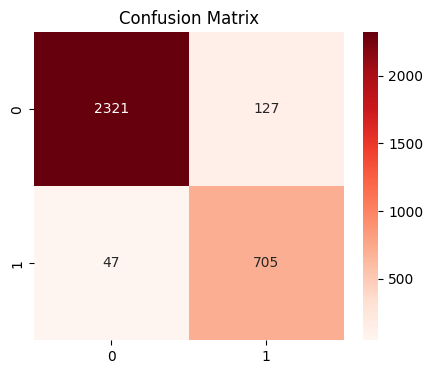

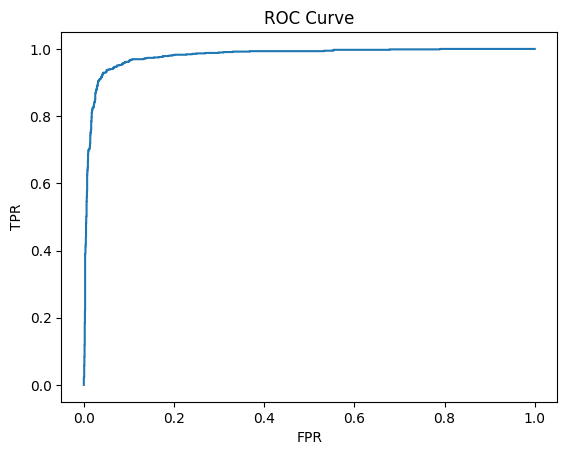

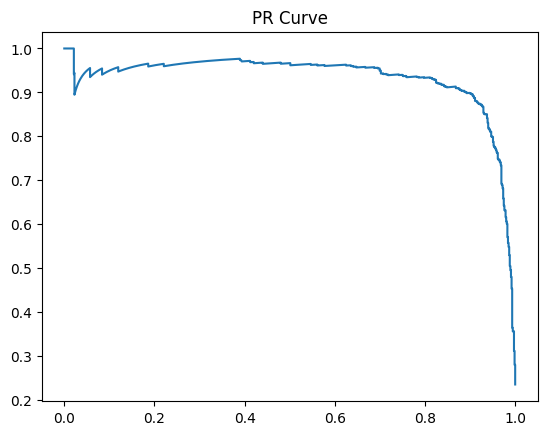

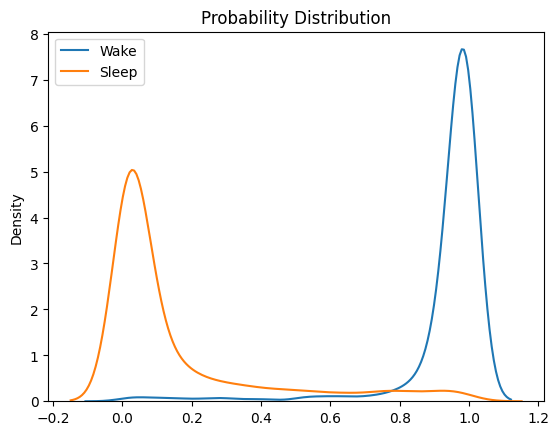

In [ ]:
# 라이브러리 로
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, numpy as np, tensorflow as tf, gc
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import *
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, filtfilt

# 하이퍼파라미터 설정
BATCH_SIZE = 32
SAMPLING_RATE = 256
SEQ_SEC = 5
STRIDE_SEC = 5
SEQ_LEN = SAMPLING_RATE * SEQ_SEC # 1280

# 데이터 준비 (드라이브에서 로컬로 복사)
drive_dir = "/content/drive/MyDrive/sleep-telemetry/muse_merge_dataset_tel"
local_dir = "/content/dataset"
os.makedirs(local_dir, exist_ok=True)

target_ids = ["011J0","021J0","041J0","051J0","061J0","071J0","081J0","091J0",
              "101J0","111J0","121J0","131J0","141J0","151J0","161J0","171J0"]

for fid in target_ids:
    for prefix in ['X','Y']:
        src = os.path.join(drive_dir, f"{prefix}_ST7{fid}-PSG.npy")
        dst = os.path.join(local_dir, f"{prefix}_ST7{fid}-PSG.npy")
        if os.path.exists(src) and not os.path.exists(dst):
            shutil.copy(src, dst)

train_ids = target_ids[:11]
val_ids   = target_ids[11:14]
test_ids  = target_ids[14:]

# 전처리 함수 (필터 및 노이즈 검사)
def bandpass_filter(data, low=0.5, high=40, fs=256, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [low/nyq, high/nyq], btype='band')
    return filtfilt(b, a, data, axis=0)

def is_noisy(sample):
    if np.std(sample) > 10: return True
    if np.max(np.abs(sample)) > 150: return True
    return False

# 데이터 제너레이터 (데이터 불균형 해소 및 증강)
def data_generator(file_ids, is_train=True):
    while True:
        np.random.shuffle(file_ids)
        for fid in file_ids:
            x_p, y_p = os.path.join(local_dir, f"X_ST7{fid}-PSG.npy"), os.path.join(local_dir, f"Y_ST7{fid}-PSG.npy")
            if not os.path.exists(x_p): continue

            X, Y = np.load(x_p, mmap_mode='r'), np.load(y_p, mmap_mode='r')
            X_virtual = X.reshape(-1, SAMPLING_RATE, 2)
            indices = list(range(0, (len(Y)*30)-SEQ_SEC+1, STRIDE_SEC))
            np.random.shuffle(indices)

            X_batch, Y_batch = [], []
            for idx in indices:
                labels = [Y[i // 30] for i in range(idx, idx + SEQ_SEC)]
                label = 1 if labels.count(0) >= (SEQ_SEC * 0.6) else 0

                sample = X_virtual[idx:idx+SEQ_SEC].reshape(SEQ_LEN, 2).astype(np.float32)
                sample = bandpass_filter(sample)

                if is_noisy(sample): continue
                sample = (sample - sample.mean())/(sample.std()+1e-6)

                if is_train and label == 1:
                    sample += np.random.normal(0, 0.01, sample.shape)
                    sample *= np.random.uniform(0.8, 1.2)

                if is_train:
                    target = 1 if len(X_batch) < BATCH_SIZE//2 else 0
                    if label != target: continue

                X_batch.append(sample)
                Y_batch.append(label)

                if len(X_batch) == BATCH_SIZE:
                    yield np.array(X_batch), np.array(Y_batch)
                    X_batch, Y_batch = [], []
            del X, Y
            gc.collect()


# 모델 구축 (에러 없는 안정적인 구조)
def build_model():
    inputs = layers.Input(shape=(SEQ_LEN, 2))

    x = layers.Conv1D(32, 7, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(4)(x)

    x = layers.Conv1D(64, 5, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(4)(x)

    x = layers.Bidirectional(layers.GRU(32, return_sequences=True))(x)

    # Attention
    attn = layers.Dense(1, activation='tanh')(x)
    attn = layers.Softmax(axis=1)(attn)
    x = layers.Multiply()([x, attn])

    # 🔥 Lambda 대신 GlobalAveragePooling1D 사용 (저장/불러오기 에러 방지 핵심)
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dropout(0.4)(x)
    x = layers.Dense(16, activation='relu')(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 임계값 찾기 및 평가 루틴
def find_best_threshold(y_true, y_probs):
    thresholds = np.linspace(0.1, 0.9, 100)
    best_t, best_score = 0.5, 0
    for t in thresholds:
        y_pred = (y_probs > t).astype(int)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        if precision_score(y_true, y_pred, zero_division=0) >= 0.6 and recall_score(y_true, y_pred, zero_division=0) >= 0.6:
            if f1 > best_score:
                best_score, best_t = f1, t
    print(f"🎯 Best Threshold: {best_t:.3f}")
    return best_t

def evaluate(model, gen, steps=100, threshold=None):
    y_true, y_probs = [], []
    for _ in range(steps):
        x, y = next(gen)
        probs = model.predict(x, verbose=0).flatten()
        y_true.extend(y)
        y_probs.extend(probs)

    y_true, y_probs = np.array(y_true), np.array(y_probs)
    if threshold is None: return find_best_threshold(y_true, y_probs)

    y_pred = (y_probs > threshold).astype(int)
    print("\n🔥 Final Report\n", classification_report(y_true, y_pred))
    return threshold


# 학습 진행
model = build_model()

train_ds = tf.data.Dataset.from_generator(lambda: data_generator(train_ids, True),
    output_signature=(tf.TensorSpec((BATCH_SIZE, SEQ_LEN, 2), tf.float32), tf.TensorSpec((BATCH_SIZE,), tf.int32))).prefetch(1)

val_ds = tf.data.Dataset.from_generator(lambda: data_generator(val_ids, False),
    output_signature=(tf.TensorSpec((BATCH_SIZE, SEQ_LEN, 2), tf.float32), tf.TensorSpec((BATCH_SIZE,), tf.int32))).take(100)

model.fit(train_ds, validation_data=val_ds, epochs=50, steps_per_epoch=300,
          callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)])

# 평가 및 최종 저장
val_gen = data_generator(val_ids, False)
best_t = evaluate(model, val_gen)

test_gen = data_generator(test_ids, False)
evaluate(model, test_gen, threshold=best_t)

save_path = '/content/drive/MyDrive/sleep-telemetry/MUSE2_Attention_Final.keras'
weights_path = '/content/drive/MyDrive/sleep-telemetry/MUSE2_Attention_Weights.weights.h5'

model.save(save_path)

model.save_weights(weights_path)

print(f"\n✅ 졸업 작품 모델 저장 완료: {save_path}")
print(f"✅ 가중치 전용 파일 저장 완료: {weights_path}")
print(f"🎯 최적 임계값({best_t:.3f})을 메모해두세요!")

In [ ]:
save_path = '/content/drive/MyDrive/sleep-telemetry/MUSE2_Attention_Final.keras'

model.save(save_path)

print(f" 졸업 작품 모델 저장 완료: {save_path}")

✅ 졸업 작품 모델 저장 완료: /content/drive/MyDrive/sleep-telemetry/MUSE2_Attention_Final.keras
이제 코랩 세션이 끊겨도 안심하셔도 됩니다!


#데이터분포

In [ ]:
import os
import numpy as np
import pandas as pd

def analyze_dataset_distribution(data_dir, target_ids):
    print(f"📂 데이터 경로: {data_dir} 분석 시작...")

    report = []
    total_wake_count = 0
    total_sleep_count = 0

    for fid in target_ids:
        y_path = os.path.join(data_dir, f"Y_ST7{fid}-PSG.npy")

        if os.path.exists(y_path):
            # 메모리 절약을 위해 mmap_mode 사용
            y_raw = np.load(y_path, mmap_mode='r')

            # Sleep-EDF 원본 기준: 0(Wake), 그 외(1, 2, 3, 4, R... -> Sleep)
            wake_cnt = np.sum(y_raw == 0)
            sleep_cnt = np.sum(y_raw != 0)
            total = len(y_raw)

            sleep_ratio = (sleep_cnt / total) * 100

            report.append({
                'ID': fid,
                'Wake (30s)': wake_cnt,
                'Sleep (30s)': sleep_cnt,
                'Sleep Ratio (%)': round(sleep_ratio, 2)
            })

            total_wake_count += wake_cnt
            total_sleep_count += sleep_cnt
        else:
            print(f"⚠️ Warning: {fid}의 라벨 파일이 없습니다.")

    # 결과 출력 (표 형식)
    df = pd.DataFrame(report)
    print("\n📊 [피험자별 데이터 분포 리포트]")
    print(df.to_string(index=False))

    print("\n" + "="*40)
    print(f"📈 [전체 데이터 요약]")
    print(f"총 Wake 샘플 수: {total_wake_count} (약 {total_wake_count*30/3600:.1f}시간)")
    print(f"총 Sleep 샘플 수: {total_sleep_count} (약 {total_sleep_count*30/3600:.1f}시간)")
    overall_ratio = (total_sleep_count / (total_wake_count + total_sleep_count)) * 100
    print(f"전체 평균 졸음 비율: {overall_ratio:.2f}%")
    print("="*40)

    return df

# 분석 실행
dist_df = analyze_dataset_distribution('/content/dataset', target_ids)

📂 데이터 경로: /content/dataset 분석 시작...

📊 [피험자별 데이터 분포 리포트]
   ID  Wake (30s)  Sleep (30s)  Sleep Ratio (%)
011J0        9255        26615            74.20
021J0        5063        25507            83.44
041J0        2590        28540            91.68
051J0        3867        28303            87.98
061J0        3776        28764            88.40
071J0       12782        14648            53.40
081J0        4902        24068            83.08
091J0        5762        24068            80.68
101J0        5613        27317            82.95
111J0        2226        29144            92.90
121J0        2502        28668            91.97
131J0        2401        25229            91.31
141J0        3147        24433            88.59
151J0       14715        23765            61.76
161J0        5300        27970            84.07
171J0        6758        22142            76.62

📈 [전체 데이터 요약]
총 Wake 샘플 수: 90659 (약 755.5시간)
총 Sleep 샘플 수: 409181 (약 3409.8시간)
전체 평균 졸음 비율: 81.86%


#problem

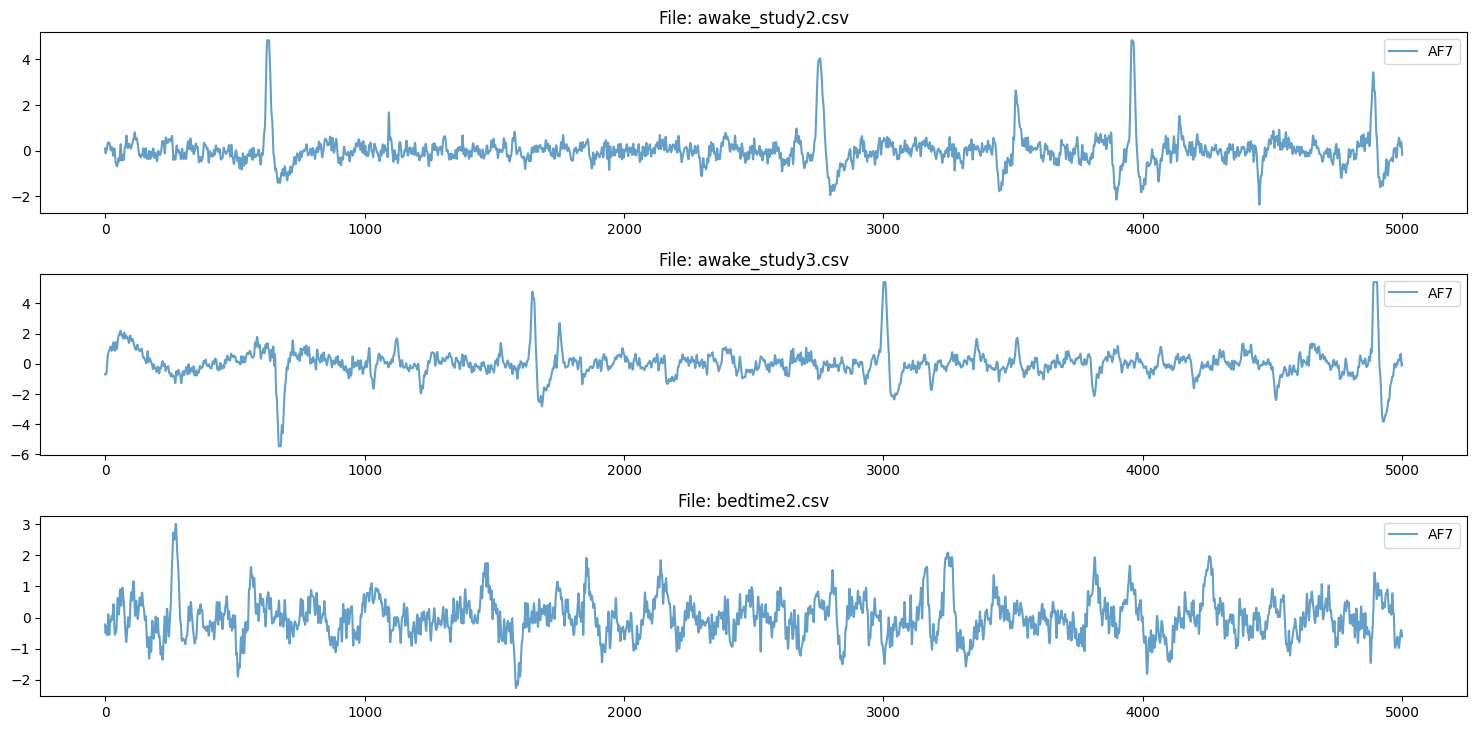

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# 기존 전처리 함수 (시각화용)
def bandpass(x):
    nyq = 0.5 * 256 # FS
    b, a = butter(4, [0.5/nyq, 40/nyq], btype='band')
    return filtfilt(b, a, x, axis=0)

def preprocess(x):
    x = bandpass(x)
    x = x - np.median(x, axis=0)
    x = np.clip(x, -100, 100)
    x = (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-6)
    return x

# 시각화할 파일 리스트
files = [
    "/content/awake_study2.csv",
    "/content/awake_study3.csv",
    "/content/bedtime2.csv",
]

# 5개 파일을 한 번에 시각화
plt.figure(figsize=(15, 12))

for i, f in enumerate(files):
    try:
        df = pd.read_csv(f)
        data = preprocess(df[['AF7', 'AF8']].values.astype(np.float32))

        plt.subplot(5, 1, i + 1)
        # 데이터가 너무 길면 처음 5000개만 샘플링하여 표시
        plt.plot(data[:5000, 0], label='AF7', alpha=0.7)
        plt.title(f"File: {f.split('/')[-1]}")
        plt.legend(loc='upper right')
    except Exception as e:
        print(f"파일을 읽을 수 없습니다: {f} - {e}")

plt.tight_layout()
plt.show()

#최적의 모델

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, shutil, numpy as np, tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from scipy.signal import butter, filtfilt
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
# 1. 설정 및 경로
DRIVE_DIR = "/content/drive/MyDrive/sleep-telemetry/muse_merge_dataset_tel"
LOCAL_DIR = "/content/dataset"
os.makedirs(LOCAL_DIR, exist_ok=True)

SEQ_LEN = 1280
BATCH_SIZE = 16
FS = 256

# 2. 전처리 함수
def bandpass(x):
    nyq = 0.5 * FS
    b, a = butter(4, [0.5/nyq, 40/nyq], btype='band')
    # x: (Samples, Time, Channels) -> axis=1이 Time 축
    return filtfilt(b, a, x, axis=1)

def preprocess(x):
    x = bandpass(x)
    # 중앙값 제거 및 클리핑
    x = x - np.median(x, axis=1, keepdims=True)
    x = np.clip(x, -100, 100)
    # Z-score 정규화
    x = (x - x.mean(axis=1, keepdims=True)) / (x.std(axis=1, keepdims=True) + 1e-6)
    return x.astype(np.float32)

target_ids = ["011J0","021J0","041J0","051J0","061J0","071J0","081J0","091J0",
              "101J0","111J0","121J0","131J0","141J0","151J0","161J0","171J0"]

In [ ]:
print("📂 데이터 복사 중...")
for fid in target_ids:
    for p in ['X', 'Y']:
        src = os.path.join(DRIVE_DIR, f"{p}_ST7{fid}-PSG.npy")
        dst = os.path.join(LOCAL_DIR, f"{p}_ST7{fid}-PSG.npy")
        if os.path.exists(src) and not os.path.exists(dst):
            shutil.copy(src, dst)

📂 데이터 복사 중...


In [ ]:
train_ids = target_ids[:11]
val_ids = target_ids[11:14]

In [ ]:
SEQ_LEN = 1280
BATCH_SIZE = 16
FS = 256

def bandpass(x):
    nyq = 0.5 * FS
    b, a = butter(4, [0.5/nyq, 40/nyq], btype='band')
    return filtfilt(b, a, x, axis=1)

def preprocess(x):
    x = bandpass(x)
    x = x - np.median(x, axis=1, keepdims=True)
    x = np.clip(x, -100, 100)
    x = (x - x.mean(axis=1, keepdims=True)) / (x.std(axis=1, keepdims=True)+1e-6)
    return x.astype(np.float32)

EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    min_delta=0.001,
    verbose=1
)

def generator(ids):
    while True:
        for fid in ids:
            x_p = os.path.join(LOCAL_DIR, f"X_ST7{fid}-PSG.npy")
            y_p = os.path.join(LOCAL_DIR, f"Y_ST7{fid}-PSG.npy")

            if not os.path.exists(x_p):
                continue

            X = np.load(x_p, mmap_mode='r')
            Y = np.load(y_p)

            X = X.reshape(-1, SEQ_LEN, 2)
            Y = (Y == 0).astype(int)

            m = min(len(X), len(Y))
            X, Y = X[:m], Y[:m]

            for i in range(0, len(X)-BATCH_SIZE, BATCH_SIZE):
                xb = preprocess(X[i:i+BATCH_SIZE])
                yb = Y[i:i+BATCH_SIZE]
                yield xb, yb

def train_gen():
    ids = ["011J0","021J0","041J0","051J0","061J0","071J0","081J0","091J0",
           "101J0","111J0","121J0"]
    return generator(ids)

def val_gen():
    return generator(val_ids)

train_ds = tf.data.Dataset.from_generator(
    train_gen,
    output_signature=(
        tf.TensorSpec((BATCH_SIZE, SEQ_LEN, 2), tf.float32),
        tf.TensorSpec((BATCH_SIZE,), tf.int32)
    )
).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_generator(
    val_gen,
    output_signature=(
        tf.TensorSpec((BATCH_SIZE, SEQ_LEN, 2), tf.float32),
        tf.TensorSpec((BATCH_SIZE,), tf.int32)
    )
).take(50).prefetch(tf.data.AUTOTUNE)

def build():
    i = layers.Input((SEQ_LEN, 2))
    x = layers.Conv1D(32, 7, padding='same', activation='relu')(i)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(4)(x)
    x = layers.Conv1D(64, 5, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(4)(x)
    x = layers.Bidirectional(layers.GRU(32, return_sequences=True))(x)
    a = layers.Dense(1, activation='tanh')(x)
    a = layers.Softmax(axis=1)(a)
    x = layers.Multiply()([x, a])
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(16, activation='relu')(x)
    o = layers.Dense(1, activation='sigmoid')(x)
    m = models.Model(i, o)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='binary_crossentropy',
              metrics=['accuracy'])
    return m

model = build()

model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=200,
    epochs=30,
    callbacks=[EarlyStopping(patience=3, restore_best_weights=True)]
)

model.save("/content/drive/MyDrive/MUSE_pretrained_2.keras")
model.save_weights("/content/drive/MyDrive/MUSE_pretrained_weights_2.weights.h5")

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.5275 - loss: 0.6954 - val_accuracy: 0.6125 - val_loss: 0.6919
Epoch 2/30
  7/200 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8772 - loss: 0.6906

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.7312 - loss: 0.6812 - val_accuracy: 0.3358 - val_loss: 0.6918
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9334 - loss: 0.6065 - val_accuracy: 0.3358 - val_loss: 0.7354
Epoch 4/30
193/200 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9987 - loss: 0.5288

KeyboardInterrupt: 

#Finetuning

🔥 GLOBAL ACTIVITY THRESHOLD
LOW : 0.5054811359766125
HIGH: 0.8689420705191669
Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.5238 - loss: 0.6931 - val_accuracy: 0.5375 - val_loss: 0.6916
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step - accuracy: 0.8363 - loss: 0.6898 - val_accuracy: 0.8156 - val_loss: 0.6889
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9700 - loss: 0.6839 - val_accuracy: 0.8438 - val_loss: 0.6839
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.9062 - loss: 0.6791 - val_accuracy: 0.8344 - val_loss: 0.6803
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.9750 - loss: 0.6723 - val_accuracy: 0.8125 - val_loss: 0.6736
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.9750 - loss: 0.6680 - val_accuracy: 0.8781 - val_loss: 0.6692
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.9962 - loss: 0.6627 - val_accuracy: 0.9469 - val_loss: 0.6650
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━

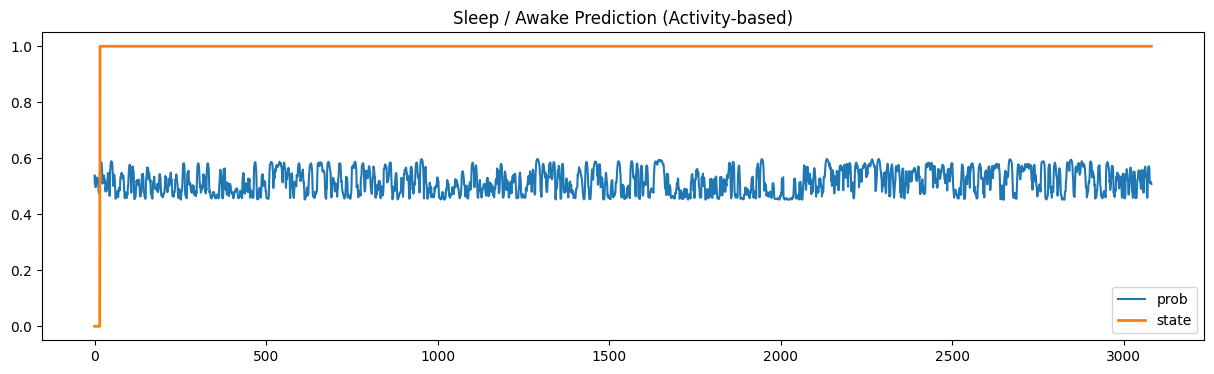

In [ ]:
import os, random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt


FS = 256
SEQ_LEN = FS * 5
STRIDE = FS
BATCH_SIZE = 32

MODEL_PATH = "/content/drive/MyDrive/MUSE_pretrained_2.keras"
SAVE_PATH  = "/content/drive/MyDrive/MUSE_activity_model.keras"

train_files = [
    "/content/bedtime2.csv",
    "/content/awake_study2.csv"
]

val_files = [
    "/content/awake_study3.csv"
]

# 전처리
def bandpass(x):
    nyq = 0.5 * FS
    b, a = butter(4, [0.5/nyq, 40/nyq], btype='band')
    return filtfilt(b, a, x, axis=0)

def preprocess(x):
    x = bandpass(x)
    x = x - np.median(x, axis=0)
    x = np.clip(x, -100, 100)
    x = (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-6)
    return x

def is_valid(signal, thr=1e-3):
    return np.std(signal) > thr

# Activity 기반 feature
def get_activity(window):
    return np.mean(np.abs(np.diff(window)))

def get_spike_ratio(window, thr=2.5):
    return np.mean(np.abs(window) > thr)

# GLOBAL activity 수집
def collect_all_activity(files):
    acts = []

    for f in files:
        d = pd.read_csv(f)[['AF7','AF8']].values.astype(np.float32)
        d = preprocess(d)

        for i in range(0, len(d) - SEQ_LEN, STRIDE):
            w = d[i:i+SEQ_LEN]

            if not is_valid(w):
                continue

            act = get_activity(w)
            acts.append(act)

    return np.array(acts)

all_acts = collect_all_activity(train_files)

low_thr  = np.percentile(all_acts, 30)
high_thr = np.percentile(all_acts, 70)

print("🔥 GLOBAL ACTIVITY THRESHOLD")
print("LOW :", low_thr)
print("HIGH:", high_thr)

# 라벨링
def load_and_label(csv_path, low_thr, high_thr):
    d = pd.read_csv(csv_path)[['AF7','AF8']].values.astype(np.float32)
    d = preprocess(d)

    X, Y = [], []

    for i in range(0, len(d) - SEQ_LEN, STRIDE):
        w = d[i:i+SEQ_LEN]

        if not is_valid(w):
            continue

        act = get_activity(w)

        if act < low_thr:
            X.append(w)
            Y.append(0.0)  # sleep-like
        elif act > high_thr:
            X.append(w)
            Y.append(1.0)  # awake-like

    return np.array(X), np.array(Y)

# Augmentation
def augment(x):
    noise = np.random.normal(0, 0.01, x.shape)
    scale = np.random.uniform(0.9, 1.1)
    return x * scale + noise

# Generator
def muse_generator(files, low_thr, high_thr):
    while True:
        random.shuffle(files)

        for f in files:
            X, Y = load_and_label(f, low_thr, high_thr)

            if len(X) < BATCH_SIZE:
                continue

            idx = np.random.permutation(len(X))
            X, Y = X[idx], Y[idx]

            for i in range(0, len(X) - BATCH_SIZE, BATCH_SIZE):
                batch_x = X[i:i+BATCH_SIZE]
                batch_y = Y[i:i+BATCH_SIZE]

                if np.random.rand() < 0.5:
                    batch_x = augment(batch_x)

                yield batch_x, batch_y

# Dataset
train_ds = tf.data.Dataset.from_generator(
    lambda: muse_generator(train_files, low_thr, high_thr),
    output_signature=(
        tf.TensorSpec((BATCH_SIZE, SEQ_LEN, 2), tf.float32),
        tf.TensorSpec((BATCH_SIZE,), tf.float32)
    )
).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_generator(
    lambda: muse_generator(val_files, low_thr, high_thr),
    output_signature=(
        tf.TensorSpec((BATCH_SIZE, SEQ_LEN, 2), tf.float32),
        tf.TensorSpec((BATCH_SIZE,), tf.float32)
    )
).prefetch(tf.data.AUTOTUNE)

# 모델
model = tf.keras.models.load_model(MODEL_PATH, safe_mode=False)

for layer in model.layers:
    layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)


history = model.fit(
    train_ds,
    validation_data=val_ds,
    steps_per_epoch=25,
    validation_steps=10,
    epochs=20,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True,
            verbose=1
        )
    ]
)


model.save(SAVE_PATH)

def hysteresis(pred, high=0.55, low=0.45):
    state = 0
    out = []
    for p in pred:
        if p > high:
            state = 1
        elif p < low:
            state = 0
        out.append(state)
    return np.array(out)


def visualize_prediction(csv_path, model):
    d = pd.read_csv(csv_path)[['AF7','AF8']].values.astype(np.float32)
    d = preprocess(d)

    preds = []

    for i in range(0, len(d) - SEQ_LEN, STRIDE):
        w = d[i:i+SEQ_LEN]
        w = w[np.newaxis, ...]

        p = model.predict(w, verbose=0)[0][0]
        preds.append(p)

    preds = np.array(preds)
    states = hysteresis(preds)

    plt.figure(figsize=(15,4))
    plt.plot(preds, label="prob")
    plt.plot(states, label="state", linewidth=2)
    plt.legend()
    plt.title("Sleep / Awake Prediction (Activity-based)")
    plt.show()

print("📊 검증 시각화")
visualize_prediction(val_files[0], model)

SAVE_DIR = "/content/drive/MyDrive/sleep-telemetry"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save(os.path.join(SAVE_DIR, "MUSE_activity_model.keras"))
model.save_weights(os.path.join(SAVE_DIR, "MUSE_activity_weights.weights.h5"))

📂 모델 로드 중: /content/drive/MyDrive/sleep-telemetry/MUSE_activity_model.keras
✅ 모델 로드 완료!
📊 awake_study.csv 분석 중...


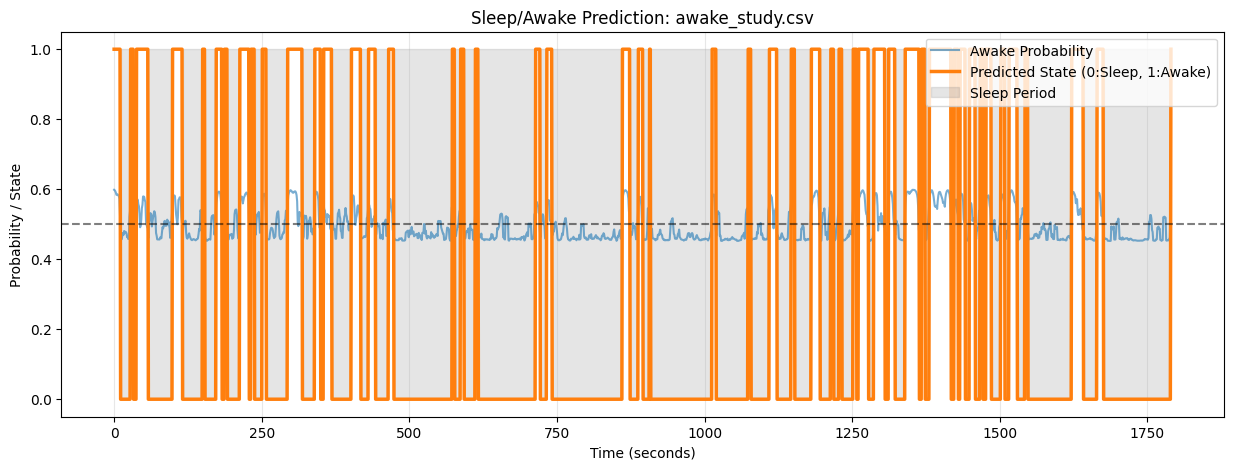

📊 bedtime.csv 분석 중...


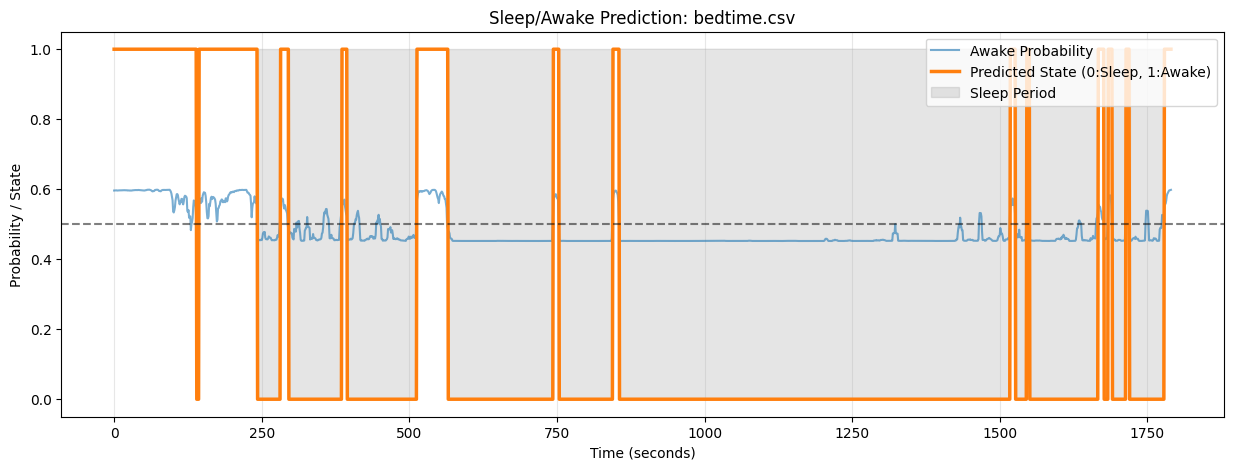

In [ ]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt


FS = 256
SEQ_LEN = FS * 5  # 5초 window
STRIDE = FS       # 1초 stride

# 저장된 최신 모델 경로
LOAD_PATH = "/content/drive/MyDrive/sleep-telemetry/MUSE_activity_model.keras"

print(f"📂 모델 로드 중: {LOAD_PATH}")
# Lambda 레이어 deserialization 허용
tf.keras.config.enable_unsafe_deserialization()
model = tf.keras.models.load_model(LOAD_PATH, safe_mode=False)
print("✅ 모델 로드 완료!")

# 예측할 새로운 파일 목록
test_files = [
    "/content/awake_study.csv",
    "/content/bedtime.csv"
]

def bandpass(x):
    nyq = 0.5 * FS
    b, a = butter(4, [0.5/nyq, 40/nyq], btype='band')
    # axis=0 확인 (데이터가 (Time, Ch) 형태일 때)
    return filtfilt(b, a, x, axis=0)

def preprocess(x):
    x = bandpass(x)
    x = x - np.median(x, axis=0)
    x = np.clip(x, -100, 100)
    x = (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-6)
    return x

def hysteresis(pred, high=0.55, low=0.45):
    state = 0
    out = []
    for p in pred:
        if p > high:
            state = 1
        elif p < low:
            state = 0
        out.append(state)
    return np.array(out)

def run_inference(csv_path, model):
    if not os.path.exists(csv_path):
        print(f"❌ 파일을 찾을 수 없습니다: {csv_path}")
        return

    print(f"📊 {os.path.basename(csv_path)} 분석 중...")


    d = pd.read_csv(csv_path)[['AF7','AF8']].values.astype(np.float32)
    d_pre = preprocess(d)

    preds = []


    for i in range(0, len(d_pre) - SEQ_LEN, STRIDE):
        w = d_pre[i:i+SEQ_LEN]
        w_batch = w[np.newaxis, ...] # (1, SEQ_LEN, 2) 배치 차원 추가

        p = model.predict(w_batch, verbose=0)[0][0]
        preds.append(p)

    preds = np.array(preds)
    states = hysteresis(preds, high=0.55, low=0.48)


    plt.figure(figsize=(15, 5))


    plt.plot(preds, label="Awake Probability", color='tab:blue', alpha=0.6)
    plt.plot(states, label="Predicted State (0:Sleep, 1:Awake)", color='tab:orange', linewidth=2.5)
    plt.fill_between(range(len(states)), 0, 1, where=(states == 0), color='gray', alpha=0.2, label="Sleep Period")

    plt.axhline(0.5, color='black', linestyle='--', alpha=0.5) # 기준선
    plt.ylim(-0.05, 1.05)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Probability / State")
    plt.title(f"Sleep/Awake Prediction: {os.path.basename(csv_path)}")
    plt.legend(loc='upper right')
    plt.grid(axis='x', alpha=0.3)
    plt.show()

for f in test_files:
    run_inference(f, model)

#result

🚀 모델 로드 중...

📊 분석 중: awake_study.csv
   - 원본 범위: 0.452 ~ 0.598
   - 변환 범위: 0.000 ~ 1.000


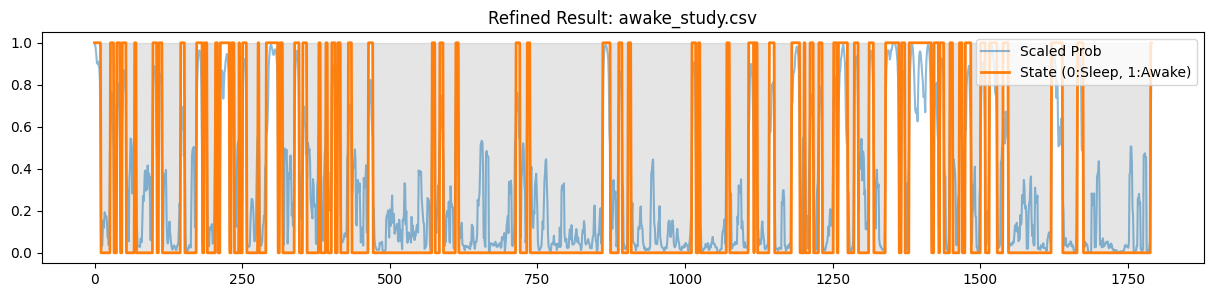


📊 분석 중: awake_study2.csv
   - 원본 범위: 0.452 ~ 0.598
   - 변환 범위: 0.000 ~ 1.000


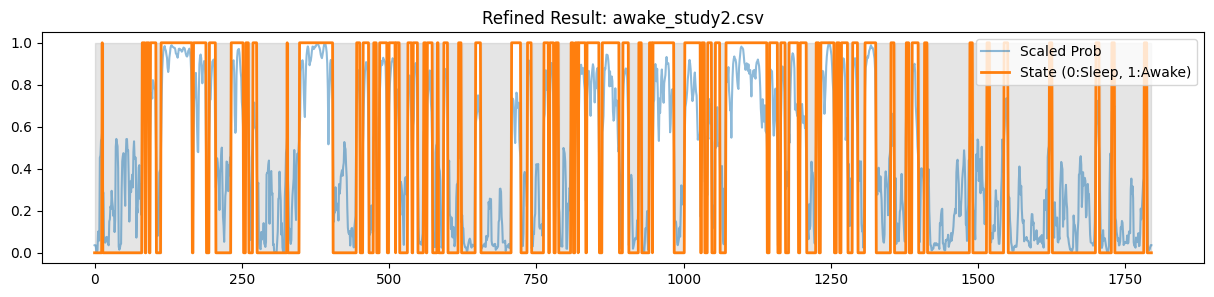


📊 분석 중: awake_study3.csv
   - 원본 범위: 0.452 ~ 0.598
   - 변환 범위: 0.000 ~ 1.000


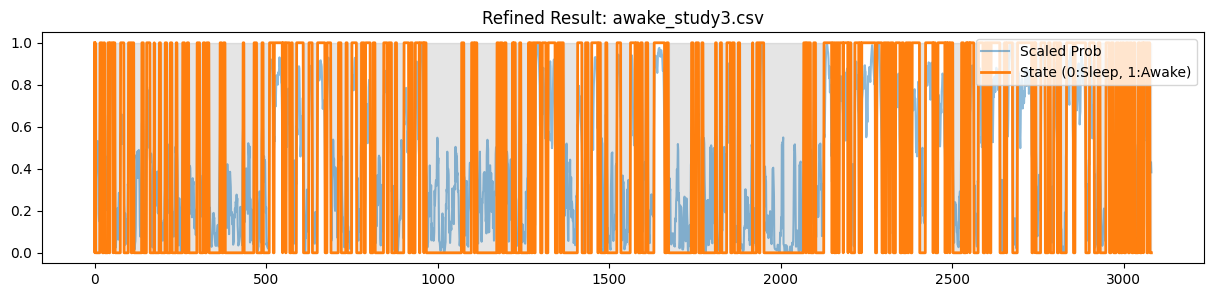


📊 분석 중: bedtime.csv
   - 원본 범위: 0.452 ~ 0.599
   - 변환 범위: 0.000 ~ 1.000


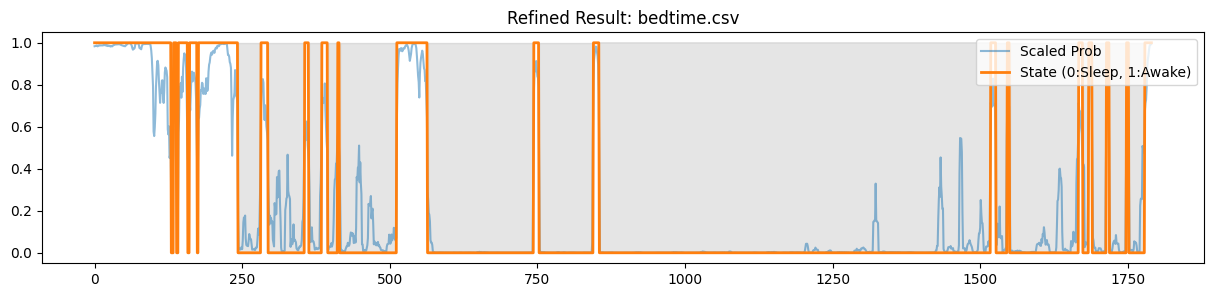


📊 분석 중: bedtime2.csv
   - 원본 범위: 0.452 ~ 0.597
   - 변환 범위: 0.000 ~ 1.000


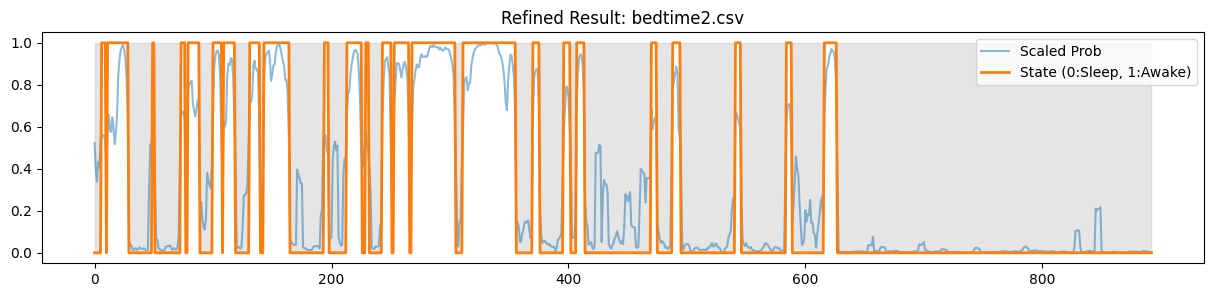

In [ ]:
import os, numpy as np, pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# 1. 설정
FS = 256
SEQ_LEN = FS * 5
STRIDE = FS
MODEL_PATH = "/content/drive/MyDrive/sleep-telemetry/MUSE_activity_model.keras"

test_files = [
    "/content/awake_study.csv",
    "/content/awake_study2.csv",
    "/content/awake_study3.csv",
    "/content/bedtime.csv",
    "/content/bedtime2.csv"
]

# 2. 핵심 함수
def preprocess(x):
    nyq = 0.5 * FS
    b, a = butter(4, [0.5/nyq, 40/nyq], btype='band')
    x = filtfilt(b, a, x, axis=0)
    x = x - np.median(x, axis=0)
    x = np.clip(x, -100, 100)
    return (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-6)

def hysteresis(pred, high=0.55, low=0.45):
    state = 0
    out = []
    for p in pred:
        if p > high: state = 1
        elif p < low: state = 0
        out.append(state)
    return np.array(out)

# 3. 추론 실행 (Min-Max Scaling 추가)
def run_all_inference_v2():
    print("🚀 모델 로드 중...")
    model = tf.keras.models.load_model(MODEL_PATH, compile=False, safe_mode=False)

    for csv_path in test_files:
        if not os.path.exists(csv_path): continue

        print(f"\n📊 분석 중: {os.path.basename(csv_path)}")
        df = pd.read_csv(csv_path)[['AF7','AF8']].values.astype(np.float32)
        d_pre = preprocess(df)

        windows = np.array([d_pre[i:i+SEQ_LEN] for i in range(0, len(d_pre) - SEQ_LEN, STRIDE)])
        preds = model.predict(windows, batch_size=128, verbose=0).flatten()

        # [핵심] 확률값 분포를 강제로 0~1 전체로 펼침
        preds_scaled = (preds - np.min(preds)) / (np.max(preds) - np.min(preds) + 1e-6)

        # [핵심] 0.5를 기준으로 확실하게 나누도록 설정
        states = hysteresis(preds_scaled, high=0.55, low=0.45)

        print(f"   - 원본 범위: {preds.min():.3f} ~ {preds.max():.3f}")
        print(f"   - 변환 범위: {preds_scaled.min():.3f} ~ {preds_scaled.max():.3f}")

        # 시각화
        plt.figure(figsize=(15, 3))
        plt.plot(preds_scaled, label="Scaled Prob", color='tab:blue', alpha=0.5)
        plt.plot(states, label="State (0:Sleep, 1:Awake)", color='tab:orange', linewidth=2)
        plt.fill_between(range(len(states)), 0, 1, where=(states == 0), color='gray', alpha=0.2)
        plt.title(f"Refined Result: {os.path.basename(csv_path)}")
        plt.legend(loc='upper right')
        plt.show()

run_all_inference_v2()

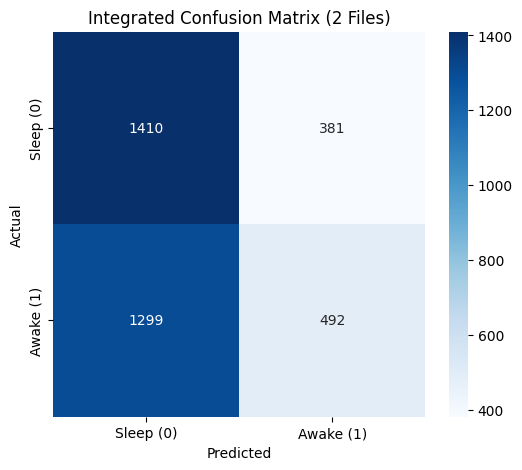


🔥 상세 평가 보고서:
              precision    recall  f1-score   support

       Sleep       0.52      0.79      0.63      1791
       Awake       0.56      0.27      0.37      1791

    accuracy                           0.53      3582
   macro avg       0.54      0.53      0.50      3582
weighted avg       0.54      0.53      0.50      3582



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns


test_files = [
    "/content/awake_study.csv",
    "/content/bedtime.csv",
]

def plot_integrated_confusion_matrix(all_files):
    all_y_true = []
    all_y_pred = []

    # 모델 로드
    model = tf.keras.models.load_model(MODEL_PATH, compile=False, safe_mode=False)

    for csv_path in all_files:
        df = pd.read_csv(csv_path)[['AF7','AF8']].values.astype(np.float32)
        d_pre = preprocess(df)
        windows = np.array([d_pre[i:i+SEQ_LEN] for i in range(0, len(d_pre) - SEQ_LEN, STRIDE)])

        preds = model.predict(windows, batch_size=128, verbose=0).flatten()
        preds_scaled = (preds - np.min(preds)) / (np.max(preds) - np.min(preds) + 1e-6)
        states = hysteresis(preds_scaled, high=0.55, low=0.45)

        label = 1 if 'awake' in csv_path else 0

        all_y_pred.extend(states)
        all_y_true.extend([label] * len(states))

    # 혼동 행렬 계산
    cm = confusion_matrix(all_y_true, all_y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Sleep (0)', 'Awake (1)'],
                yticklabels=['Sleep (0)', 'Awake (1)'])
    plt.title('Integrated Confusion Matrix (2 Files)')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    print("\n🔥 상세 평가 보고서:")
    print(classification_report(all_y_true, all_y_pred, target_names=['Sleep', 'Awake']))

# 실행
plot_integrated_confusion_matrix(test_files)